# 09.6 · Fine-tuning a small model on ShopWave reviews

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/09-nlp-genai/06-fine-tuning/lesson.ipynb)

Read the [README](README.md) first. This notebook fine-tunes DistilBERT on 2,000 labelled reviews with a plain PyTorch training loop (the same loop as Module 08), then compares it with everything else in the module.

**Time:** about 30 seconds on a laptop GPU (Apple or NVIDIA), roughly 2 to 10 minutes on a laptop CPU. On Colab, choose a GPU runtime.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os, logging, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, str(data_path("download.py").parent))

In [2]:
import transformers
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()

import torch, time
torch.manual_seed(42)
device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
print("training on", device)

training on mps


In [3]:
from download import load_reviews
from sklearn.model_selection import train_test_split

reviews = load_reviews()          # first run downloads one 117 MB file, then cached
train, test = train_test_split(reviews, test_size=0.2, random_state=42, stratify=reviews["label"])
print(f"{len(reviews):,} reviews ({reviews['label'].mean():.0%} positive): "
      f"train {len(train):,} / test {len(test):,}")
reviews[["text", "label"]].head()

10,000 reviews (50% positive): train 8,000 / test 2,000


,text,label
0,"Great Book, Must read! Ramon found the fabulou...",1
1,A leaker! This is the second generation of the...,0
2,Not For the Professional Cook. Henckels are we...,0
3,Arg! I'd like to see Robert Jordan put to the ...,0
4,"If I could give this minus 5 stars, I'd give i...",0


In [4]:
N_TRAIN = 2000          # on a slow laptop CPU, 1000 halves the training time
small = train.groupby("label").sample(N_TRAIN // 2, random_state=42).sample(frac=1, random_state=42)
print(f"fine-tuning on {len(small):,} reviews, testing on {len(test):,}")

fine-tuning on 2,000 reviews, testing on 2,000


## 1. A pretrained body with a brand-new head

In [5]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

CHECKPOINT = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

def batches(texts, size):
    for i in range(0, len(texts), size):
        yield i, tokenizer(list(texts[i:i + size]), truncation=True, max_length=128,
                           padding=True, return_tensors="pt").to(device)

def train_one_epoch(model, texts, labels, lr=5e-5, batch_size=16):
    optimiser = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    labels, losses = torch.tensor(labels), []
    model.train()
    for i, batch in batches(texts, batch_size):
        loss = model(**batch, labels=labels[i:i + batch_size].to(device)).loss
        loss.backward(); optimiser.step(); optimiser.zero_grad()
        losses.append(loss.item())
    return losses

def predict_proba(model, texts, batch_size=64):
    model.eval(); out = []
    with torch.no_grad():
        for _, batch in batches(texts, batch_size):
            out.append(torch.softmax(model(**batch).logits, dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(out)

model = AutoModelForSequenceClassification.from_pretrained(CHECKPOINT, num_labels=2).to(device)
total = sum(p.numel() for p in model.parameters())
head = sum(p.numel() for n, p in model.named_parameters() if "classifier" in n)
print(f"{total:,} parameters in total; {head:,} in the new classification head ({head / total:.1%})")

66,955,010 parameters in total; 592,130 in the new classification head (0.9%)


The head starts random, so before training the model is guessing. Its loss should be close to $\ln 2 = 0.693$:

In [6]:
p_before = predict_proba(model, test["text"].tolist())
print(f"accuracy before fine-tuning: {np.mean((p_before > 0.5) == test['label'].to_numpy()):.1%}")

accuracy before fine-tuning: 41.8%


## 2. Fine-tune: one pass over 2,000 reviews

125 steps in 11 s
average loss: first 10 steps 0.694, last 10 steps 0.189


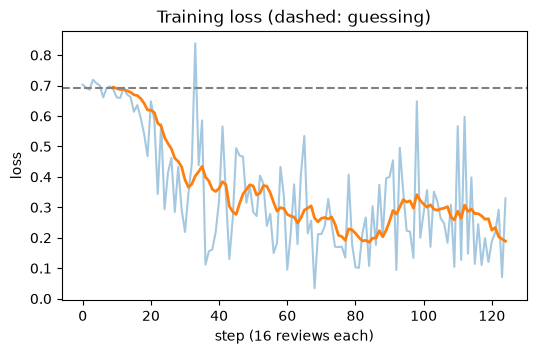

In [7]:
start = time.time()
losses = train_one_epoch(model, small["text"].tolist(), small["label"].tolist())
print(f"{len(losses)} steps in {time.time() - start:.0f} s")
print(f"average loss: first 10 steps {np.mean(losses[:10]):.3f}, last 10 steps {np.mean(losses[-10:]):.3f}")
plt.figure(figsize=(6, 3.5))
plt.plot(losses, alpha=.4); plt.plot(pd.Series(losses).rolling(10).mean(), lw=2)
plt.axhline(np.log(2), ls="--", c="grey"); plt.xlabel("step (16 reviews each)"); plt.ylabel("loss")
plt.title("Training loss (dashed: guessing)"); plt.show()

In [8]:
p_after = predict_proba(model, test["text"].tolist())
finetuned_acc = np.mean((p_after > 0.5) == test["label"].to_numpy())
print(f"accuracy after fine-tuning on {len(small):,} reviews: {finetuned_acc:.1%}")

accuracy after fine-tuning on 2,000 reviews: 90.6%


## 3. The scoreboard: everything on the same 2,000 test reviews

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from transformers import pipeline

tfidf_small = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), LogisticRegression(max_iter=1000))
tfidf_small.fit(small["text"], small["label"])
zero = pipeline("zero-shot-classification", model="typeform/distilbert-base-uncased-mnli", device=device)
zs = zero(test["text"].tolist(), candidate_labels=["positive", "negative"], batch_size=32, truncation=True)
zero_acc = np.mean([(o["labels"][0] == "positive") == (y == 1) for o, y in zip(zs, test["label"])])

In [10]:
board = pd.DataFrame([
    ("zero-shot (no training, 09.5 router model)", "none", zero_acc),
    ("TF-IDF + logistic regression", f"{len(small):,} reviews", np.mean(tfidf_small.predict(test["text"]) == test["label"])),
    ("ready-made sentiment model (film reviews, 09.5)", "none by us", 0.890),
    ("DistilBERT fine-tuned here", f"{len(small):,} reviews", finetuned_acc),
], columns=["method", "our labelled data", "test accuracy"])
board["test accuracy"] = board["test accuracy"].map("{:.1%}".format)
board

,method,our labelled data,test accuracy
0,"zero-shot (no training, 09.5 router model)",none,81.7%
1,TF-IDF + logistic regression,"2,000 reviews",84.7%
2,"ready-made sentiment model (film reviews, 09.5)",none by us,89.0%
3,DistilBERT fine-tuned here,"2,000 reviews",90.6%


The ready-made model's 89.0% is copied from 09.5 rather than re-run, to save time.

## 4. The tricky sentences again

In [11]:
tricky = ["This is not good.", "Not bad at all, I'm pleasantly surprised.",
          "Oh great, another charger that died after a week. Just what I needed.",
          "I can't fault this cake stand at all.", "Brilliant, the mug arrived in three pieces."]
for review, p in zip(tricky, predict_proba(model, tricky)):
    print(f"P(positive) = {p:.3f}   {review}")

P(positive) = 0.023   This is not good.
P(positive) = 0.587   Not bad at all, I'm pleasantly surprised.
P(positive) = 0.862   Oh great, another charger that died after a week. Just what I needed.
P(positive) = 0.179   I can't fault this cake stand at all.
P(positive) = 0.947   Brilliant, the mug arrived in three pieces.


## 5. Save it for later

In [12]:
from pathlib import Path
save_dir = data_path("download.py").parent.parent / "models" / "shopwave-sentiment-distilbert"
model.save_pretrained(save_dir); tokenizer.save_pretrained(save_dir)
print("saved to", save_dir.relative_to(save_dir.parents[1]),
      f"({sum(f.stat().st_size for f in save_dir.iterdir()) / 1e6:.0f} MB)")

saved to models/shopwave-sentiment-distilbert (269 MB)


`models/` is git-ignored. Load it again with `AutoModelForSequenceClassification.from_pretrained(save_dir)`; Module 10 serves a model like this behind an API.

## Quiz answers

1. Keep the pretrained network (which already knows the language), add a small new output layer for your task, and continue training everything on your labelled examples with a small learning rate.
2. The new head starts random, so the model outputs about 50/50; the loss for a 50/50 guess on the true class is $-\ln 0.5 = 0.693$.
3. A large learning rate makes big changes to weights that already encode useful knowledge and can wipe it out (sometimes called catastrophic forgetting); fine-tuning nudges them.
4. When you have a clear, stable, high-volume task and at least a few hundred labelled examples: it is cheaper per prediction, faster, private, and often more accurate than prompting a large general model.
5. Any two of: very little labelled data; the task changes often; you need explanations or free-form output; you lack a GPU or the time to maintain a model.

**Next:** [09.7 How large language models work](../07-how-llms-work/)